# 04. Modeling, Evaluation & OLS Diagnostics
**Objective:** Train and evaluate linear forecasting models on out-of-time test data (`2019–2023`) via a structured Ablation Study, benchmark against SMART objectives (`Adj. R² >= 0.80`, `RMSE <= 40`, `MAPE < 10%`), verify the 4 classical OLS assumptions, and analyze sector-level forecast errors.

### Pipeline Checklist:
- [ ] Load verified `train`/`test` feature matrices & verify metadata alignment
- [ ] Run Systematic Ablation Study (`Baseline t` → `+ Sector` → `+ Sector × t` → `+ Month`)
- [ ] Inspect OLS Summary & interpret domain coefficients (Trillion BTU)
- [ ] Validate 4 Classical OLS Assumptions (VIF, Breusch-Pagan, Durbin-Watson/BG, Jarque-Bera) + Remediation
- [ ] Visualize Out-of-Time Forecasts (`2019–2023`) & conduct Sector-Level Error Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [3]:
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

In [4]:
PROCESSED_DIR = Path('../data/processed')
FIGURES_DIR = Path('../reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")
X_train_scaled = pd.read_csv(PROCESSED_DIR / "X_train_scaled.csv")
X_test_scaled = pd.read_csv(PROCESSED_DIR / "X_test_scaled.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")["Total Renewable Energy"]
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv")["Total Renewable Energy"]

df_clean = pd.read_csv(PROCESSED_DIR / "renewable_clean.csv")
meta_train = df_clean[df_clean["Year"] <= 2018][
    ["Year", "Month", "Sector", "Total Renewable Energy"]
].reset_index(drop=True)
meta_test = df_clean[df_clean["Year"] > 2018][
    ["Year", "Month", "Sector", "Total Renewable Energy"]
].reset_index(drop=True)

In [6]:
assert X_train.shape[0] == len(y_train) == len(meta_train), "Train row alignment mismatch!"
assert X_test.shape[0] == len(y_test) == len(meta_test), "Test row alignment mismatch!"
assert np.allclose(meta_train['Total Renewable Energy'], y_train), "y_train ordering mismatch!"
assert np.allclose(meta_test['Total Renewable Energy'], y_test), "y_test ordering mismatch!"

print(f"Loaded Train: X={X_train.shape}, y={y_train.shape} ({meta_train['Year'].min()}–{meta_train['Year'].max()})")
print(f"Loaded Test : X={X_test.shape},  y={y_test.shape}  ({meta_test['Year'].min()}–{meta_test['Year'].max()})")
print(f"Target min -> Train: {y_train.min():.3f} | Test: {y_test.min():.3f} Trillion BTU (zero-check for MAPE)")

Loaded Train: X=(2208, 18), y=(2208,) (1973–2018)
Loaded Test : X=(240, 18),  y=(240,)  (2019–2023)
Target min -> Train: 0.515 | Test: 16.013 Trillion BTU (zero-check for MAPE)


### 2. Systematic Ablation Study (`Model 1` → `Model 4`)
**Objective:** Progressively evaluate each engineered feature group on unseen out-of-time data (`2019–2023`) and benchmark performance against our SMART targets (`Test Adj. R² >= 0.80`, `Test RMSE <= 40 Trillion BTU`, `Test MAPE < 10%`).

In [7]:
def calc_metrics(y_true, y_pred, p):
    r2 = r2_score(y_true,y_pred)
    adj_r2 = 1 - (1 - r2) * (len(y_true) - 1) / (len(y_true) - p - 1)
    rmse = np.sqrt(mean_squared_error(y_true,y_pred))
    mae = mean_absolute_error(y_true,y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return r2, adj_r2, rmse, mae, mape

In [8]:
sector_cols = ['Sector_Electric Power', 'Sector_Industrial', 'Sector_Residential']
interaction_cols = ['Sector_Electric Power_x_t', 'Sector_Industrial_x_t', 'Sector_Residential_x_t']
month_cols = [f'Month_{m}' for m in range(2, 13)]

feature_sets = {
    'Model 1: Baseline (t)': ['t'],
    'Model 2: + Sector': ['t'] + sector_cols,
    'Model 3: + Sector x t': ['t'] + sector_cols + interaction_cols,
    'Model 4: + Month (Full)': ['t'] + sector_cols + interaction_cols + month_cols,
}


In [9]:
results = []
fitted_models = {}

for name, cols in feature_sets.items():
    model = LinearRegression()
    model.fit(X_train[cols], y_train)
    fitted_models[name] = model
    prediction = model.predict(X_train[cols])
    tr_r2, tr_adj_r2, tr_rmse, tr_mae, tr_mape = calc_metrics(
        y_train, prediction, len(cols)
    )
    te_r2, te_adj_r2, te_rmse, te_mae, te_mape = calc_metrics(
        y_test, model.predict(X_test[cols]), len(cols)
    )
    results.append(
        {
            "Model": name,
            "Features (p)": len(cols),
            "Train Adj. R²": round(tr_adj_r2, 4),
            "Test R²": round(te_r2, 4),
            "Test Adj. R²": round(te_adj_r2, 4),
            "Test RMSE": round(te_rmse, 2),
            "Test MAE": round(te_mae, 2),
            "Test MAPE (%)": round(te_mape, 2),
            "SMART R² (>=0.80)": te_adj_r2 >= 0.80,
            "SMART RMSE (<=40)": te_rmse <= 40.0,
        }
    )
ablation_df = pd.DataFrame(results)
display(ablation_df)

,Model,Features (p),Train Adj. R²,Test R²,Test Adj. R²,Test RMSE,Test MAE,Test MAPE (%),SMART R² (>=0.80),SMART RMSE (<=40)
0,Model 1: Baseline (t),1,0.0570,-0.0282,-0.0325,98.54,93.22,172.09,False,False
1,Model 2: + Sector,4,0.8752,0.6653,0.6596,56.22,40.26,47.81,False,False
2,Model 3: + Sector x t,7,0.9324,0.8524,0.8479,37.34,23.35,15.83,True,True
3,Model 4: + Month (Full),18,0.9342,0.8544,0.8426,37.08,23.35,16.60,True,True


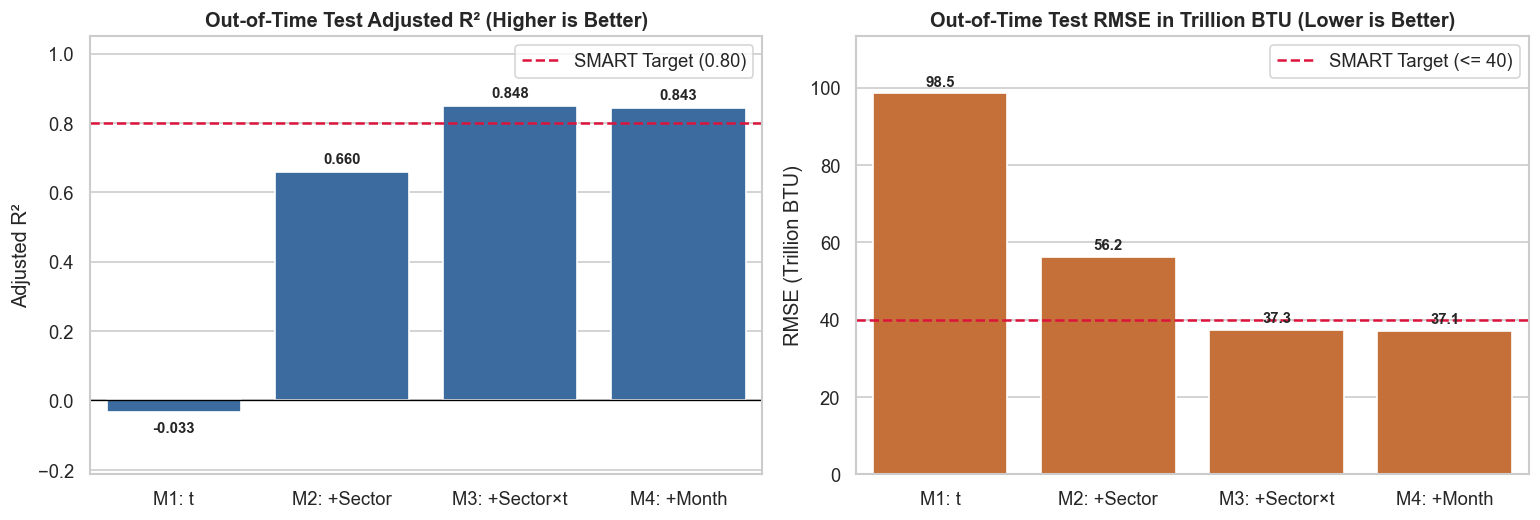

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
short_labels = ['M1: t', 'M2: +Sector', 'M3: +Sector×t', 'M4: +Month']
sns.barplot(x=short_labels, y=ablation_df['Test Adj. R²'], ax=axes[0], color='#2b6cb0')
axes[0].axhline(0.80, color='crimson', linestyle='--', linewidth=1.5, label='SMART Target (0.80)')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_ylim(min(ablation_df['Test Adj. R²'].min() - 0.18, -0.05), 1.05)
axes[0].set_title('Out-of-Time Test Adjusted R² (Higher is Better)', fontweight='bold')
axes[0].set_ylabel('Adjusted R²')
axes[0].legend()
sns.barplot(x=short_labels, y=ablation_df['Test RMSE'], ax=axes[1], color='#dd6b20')
axes[1].axhline(40.0, color='crimson', linestyle='--', linewidth=1.5, label='SMART Target (<= 40)')
axes[1].set_ylim(0, ablation_df['Test RMSE'].max() * 1.15)
axes[1].set_title('Out-of-Time Test RMSE in Trillion BTU (Lower is Better)', fontweight='bold')
axes[1].set_ylabel('RMSE (Trillion BTU)')
axes[1].legend()
for i, v in enumerate(ablation_df['Test Adj. R²']):
    axes[0].text(i, v + (0.025 if v >= 0 else -0.06), f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
for i, v in enumerate(ablation_df['Test RMSE']):
    axes[1].text(i, v + ablation_df['Test RMSE'].max() * 0.02, f'{v:.1f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_ablation_study.png', dpi=150, bbox_inches='tight')
plt.show()

### 3. OLS Statistical Inference & Domain Coefficient Interpretation
**Objective:** Fit the full feature specification (`Model 4`) using `statsmodels.OLS` to inspect feature-level statistical significance (`p-values`), overall F-statistic, and translate interaction slopes into sector-level annual growth rates (`Trillion BTU / year`).

In [11]:
X_train_const = sm.add_constant(X_train, has_constant='add')
X_test_const = sm.add_constant(X_test, has_constant='add')

ols_model = sm.OLS(y_train, X_train_const).fit()
print(ols_model.summary())


                              OLS Regression Results                              
Dep. Variable:     Total Renewable Energy   R-squared:                       0.935
Model:                                OLS   Adj. R-squared:                  0.934
Method:                     Least Squares   F-statistic:                     1742.
Date:                    Sat, 14 Nov 2026   Prob (F-statistic):               0.00
Time:                            20:05:08   Log-Likelihood:                -9287.1
No. Observations:                    2208   AIC:                         1.861e+04
Df Residuals:                        2189   BIC:                         1.872e+04
Df Model:                              18                                         
Covariance Type:                nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

In [12]:
params = ols_model.params
pvals = ols_model.pvalues

sector_growth = pd.DataFrame([
    {'Sector': 'Commercial (Baseline)', 'Monthly Slope (BTU/mo)': params['t'], 'Annual Growth (BTU/yr)': params['t'] * 12},
    {'Sector': 'Electric Power', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Electric Power_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Electric Power_x_t']) * 12},
    {'Sector': 'Industrial', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Industrial_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Industrial_x_t']) * 12},
    {'Sector': 'Residential', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Residential_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Residential_x_t']) * 12},
])

print("\nImplied Linear Growth Trajectory by Sector (1973–2018 Training Fit):")
display(sector_growth.round(4))
non_sig = pvals[pvals >= 0.05]
print(f"\nNon-significant features (p >= 0.05): {list(non_sig.index)}")


Implied Linear Growth Trajectory by Sector (1973–2018 Training Fit):


,Sector,Monthly Slope (BTU/mo),Annual Growth (BTU/yr)
0,Commercial (Baseline),4.7662,57.1941
1,Electric Power,30.7470,368.9639
2,Industrial,24.0570,288.6835
3,Residential,-2.7859,-33.4310



Non-significant features (p >= 0.05): ['Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_12']


### 4. Classical OLS Assumption Diagnostics & HAC Remediation
**Objective:** Test the four Gauss-Markov / classical OLS assumptions (Multicollinearity via VIF, Homoscedasticity via Breusch-Pagan, Autocorrelation via Durbin-Watson & Breusch-Godfrey, and Normality via Jarque-Bera), inspect residual plots, and apply **Newey-West HAC robust standard errors** for valid statistical inference.

In [13]:
resid = ols_model.resid
fitted = ols_model.fittedvalues
X_vif = X_train_const.astype(float)

vif_df = (
    pd.DataFrame(
        {
            "Feature": X_vif.columns[1:],
            "VIF": [
                variance_inflation_factor(X_vif.values, i)
                for i in range(1, X_vif.shape[1])
            ],
        }
    )
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

bp_stat, bp_pval, _, _ = het_breuschpagan(resid, X_vif)

dw_global = durbin_watson(resid)
bg_stat, bg_pval, _, _ = acorr_breusch_godfrey(ols_model, nlags=12)

sector_dw = {}

for sec in sorted(meta_train["Sector"].unique()):
    sec_mask = (meta_train["Sector"] == sec).values
    sector_dw[sec] = round(durbin_watson(resid[sec_mask]), 3)

jb_stat, jb_pval = stats.jarque_bera(resid)

assumptions_summary = pd.DataFrame(
    [
        {
            "Assumption": "1. No Multicollinearity (VIF)",
            "Metric / Test": f"Max VIF = {vif_df['VIF'].max():.2f}",
            "Threshold": "VIF < 5 (or < 10)",
            "Status": "CHECK (Structural)" if vif_df["VIF"].max() >= 5 else "PASS",
        },
        {
            "Assumption": "2. Homoscedasticity",
            "Metric / Test": f"Breusch-Pagan p = {bp_pval:.4e}",
            "Threshold": "p >= 0.05",
            "Status": "PASS" if bp_pval >= 0.05 else "FAIL (Heteroscedastic)",
        },
        {
            "Assumption": "3. No Autocorrelation",
            "Metric / Test": f"BG(12) p = {bg_pval:.4e} | DW = {dw_global:.3f}",
            "Threshold": "p >= 0.05 | DW ~ 2",
            "Status": "PASS" if bg_pval >= 0.05 else "FAIL (Autocorrelated)",
        },
        {
            "Assumption": "4. Normality of Residuals",
            "Metric / Test": f"Jarque-Bera p = {jb_pval:.4e}",
            "Threshold": "p >= 0.05",
            "Status": "PASS" if jb_pval >= 0.05 else "FAIL (Non-Normal)",
        },
    ]
)

C:\Users\micha\AppData\Local\Temp\ipykernel_11056\1738766166.py:22: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_stat, bg_pval, _, _ = acorr_breusch_godfrey(ols_model, nlags=12)


In [14]:
print("=== OLS Classical Assumption Diagnostics ===")
display(assumptions_summary)
print("Within-Sector Durbin-Watson (chronological lag-1 per sector):")
print(sector_dw)

=== OLS Classical Assumption Diagnostics ===


,Assumption,Metric / Test,Threshold,Status
0,1. No Multicollinearity (VIF),Max VIF = 6.48,VIF < 5 (or < 10),CHECK (Structural)
1,2. Homoscedasticity,Breusch-Pagan p = 6.8408e-94,p >= 0.05,FAIL (Heteroscedastic)
2,3. No Autocorrelation,BG(12) p = 0.0000e+00 | DW = 1.542,p >= 0.05 | DW ~ 2,FAIL (Autocorrelated)
3,4. Normality of Residuals,Jarque-Bera p = 1.4746e-40,p >= 0.05,FAIL (Non-Normal)


Within-Sector Durbin-Watson (chronological lag-1 per sector):
{'Commercial': np.float64(1.491), 'Electric Power': np.float64(0.176), 'Industrial': np.float64(0.39), 'Residential': np.float64(0.043)}


In [15]:
print("\nTop 8 Features by VIF:")
display(vif_df.head(8).round(2))
# Remediation: Newey-West HAC robust standard errors for valid inference under Het + Autocorr
ols_hac = sm.OLS(y_train, X_train_const).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
flipped = pd.DataFrame({
    'OLS p-value': ols_model.pvalues.round(4),
    'HAC p-value': ols_hac.pvalues.round(4),
    'Changed Sig (0.05)?': (ols_model.pvalues < 0.05) != (ols_hac.pvalues < 0.05),
})
print(f"\nFeatures whose significance (p < 0.05) changed under Newey-West HAC: {flipped['Changed Sig (0.05)?'].sum()}")
display(flipped[flipped['Changed Sig (0.05)?']] if flipped['Changed Sig (0.05)?'].any() else flipped.head(8))


Top 8 Features by VIF:


,Feature,VIF
0,Sector_Electric Power_x_t,6.48
1,Sector_Industrial_x_t,6.48
2,Sector_Residential_x_t,6.48
3,Sector_Electric Power,5.98
4,Sector_Industrial,5.98
5,Sector_Residential,5.98
6,t,4.00
7,Month_12,1.83



Features whose significance (p < 0.05) changed under Newey-West HAC: 0


,OLS p-value,HAC p-value,Changed Sig (0.05)?
const,0.0,0.0,False
t,0.0,0.0,False
Sector_Electric Power,0.0,0.0,False
Sector_Industrial,0.0,0.0,False
Sector_Residential,0.0,0.0,False
Sector_Electric Power_x_t,0.0,0.0,False
Sector_Industrial_x_t,0.0,0.0,False
Sector_Residential_x_t,0.0,0.0,False


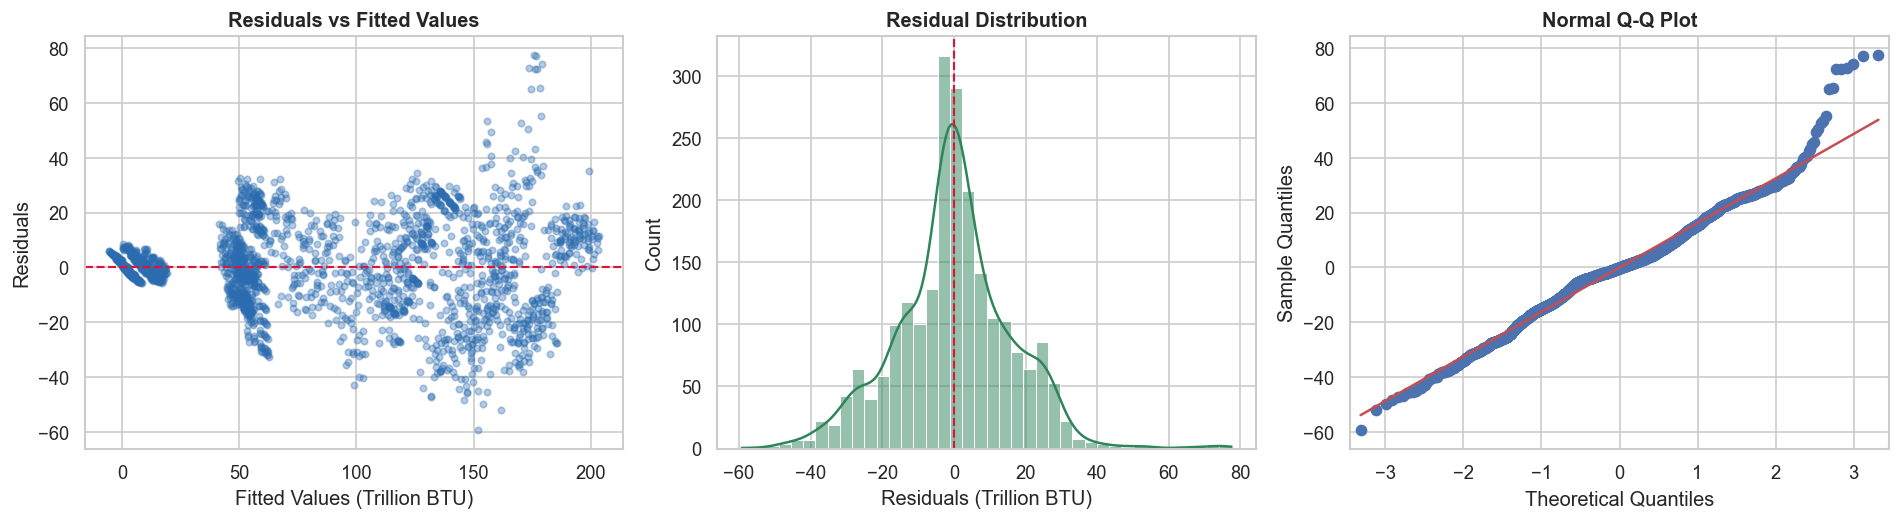

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Residuals vs Fitted (Homoscedasticity & Linearity check)
axes[0].scatter(fitted, resid, alpha=0.35, s=15, color='#2b6cb0')
axes[0].axhline(0, color='crimson', linestyle='--', linewidth=1.3)
axes[0].set_title('Residuals vs Fitted Values', fontweight='bold')
axes[0].set_xlabel('Fitted Values (Trillion BTU)')
axes[0].set_ylabel('Residuals')

# 2. Residual Distribution (Normality check)
sns.histplot(resid, kde=True, bins=40, ax=axes[1], color='#2f855a')
axes[1].axvline(0, color='crimson', linestyle='--', linewidth=1.3)
axes[1].set_title('Residual Distribution', fontweight='bold')
axes[1].set_xlabel('Residuals (Trillion BTU)')

# 3. Normal Q-Q Plot
sm.qqplot(resid, line='s', ax=axes[2])
axes[2].set_title('Normal Q-Q Plot', fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_ols_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

### 5. Out-of-Time Forecast Visualization (`2019–2023`) & Sector-Level Error Analysis
**Objective:** Disaggregate out-of-time test errors (`RMSE`, `MAE`, `MAPE`, and `Mean Bias`) across each energy sector and visualize `Actual vs OLS Forecast` trajectories (`2005–2023` view) to pinpoint structural limitations and seasonal alignment.

In [17]:
train_eval = meta_train.copy()
train_eval['Predicted'] = ols_model.predict(X_train_const).values
train_eval['Split'] = 'Train'

test_eval = meta_test.copy()
test_eval['Predicted'] = ols_model.predict(X_test_const).values
test_eval['Split'] = 'Test'



In [ ]:
sector_rows = []

for sec, grp in test_eval.groupby("Sector"):
    y_t = grp["Total Renewable Energy"]
    y_p = grp["Predicted"]
    err = y_t - y_p
    sector_rows.append(
        {
            "Sector": sec,
            "N": len(grp),
            "Mean Actual (BTU)": round(y_t.mean(), 2),
            "Mean Pred (BTU)": round(y_p.mean(), 2),
            "Mean Bias (Act - Pred)": round(err.mean(), 2),
            "MAE (BTU)": round(mean_absolute_error(y_t, y_p), 2),
            "RMSE (BTU)": round(np.sqrt(mean_squared_error(y_t, y_p)), 2),
            "MAPE (%)": round(np.mean(np.abs(err / y_t)) * 100, 2),
        }
    )
sector_error_df = pd.DataFrame(sector_rows).sort_values('RMSE (BTU)', ascending=False).reset_index(drop=True)
sector_error_df.head(10)

,Sector,N,Mean Actual (BTU),Mean Pred (BTU),Mean Bias (Act - Pred),MAE (BTU),RMSE (BTU),MAPE (%)
0,Electric Power,60,251.91,183.94,67.97,67.97,71.49,26.39
1,Industrial,60,194.22,206.33,-12.11,13.08,15.95,6.97
2,Residential,60,53.27,45.99,7.28,8.70,10.71,15.25
3,Commercial,60,20.00,16.92,3.08,3.64,4.49,17.78


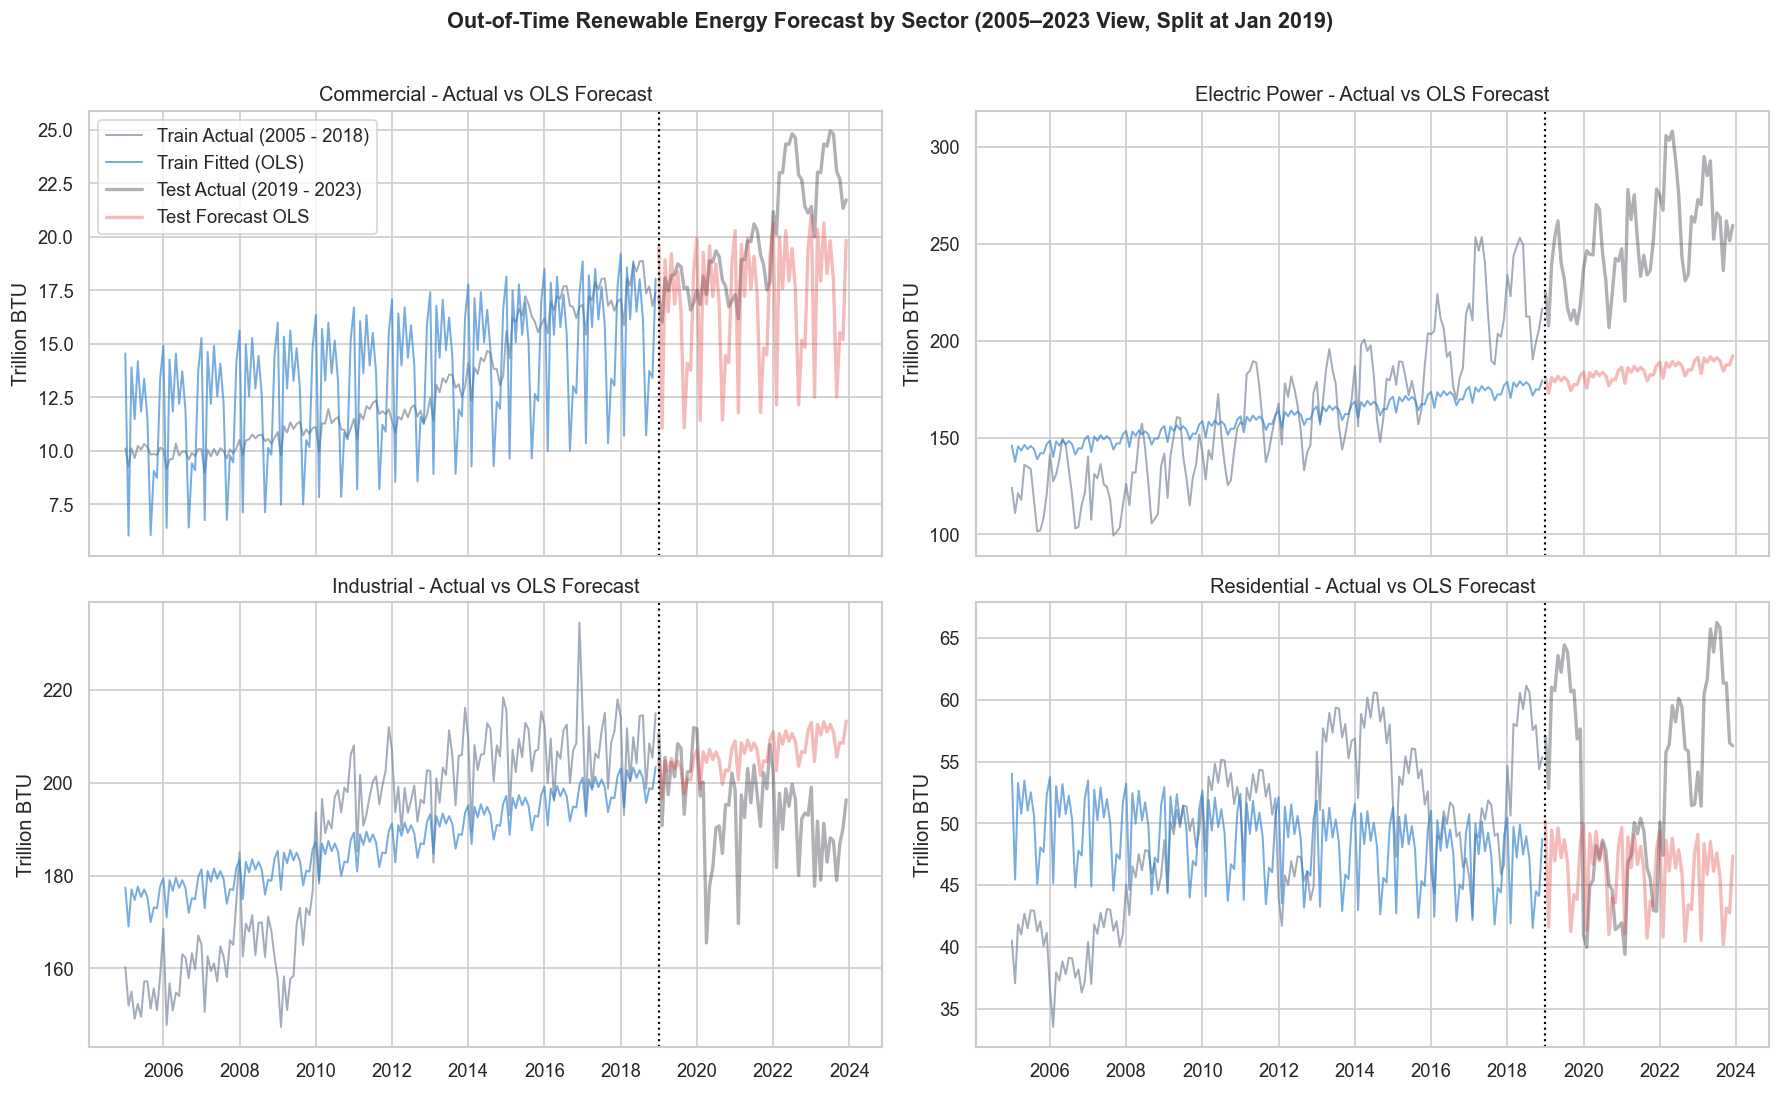

In [28]:
full_eval = pd.concat([train_eval, test_eval], ignore_index=True)
full_eval["Date"] = pd.to_datetime(
    dict(year=full_eval["Year"], month=full_eval["Month"], day=1)
)
plot_df = full_eval[full_eval["Year"] >= 2005].copy()

sectors = sorted(plot_df["Sector"].unique())
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
axes = axes.flatten()

for ax, sec in zip(axes, sectors):
    sub = plot_df[plot_df["Sector"] == sec].sort_values("Date")
    sub_tr = sub[sub["Split"] == "Train"]
    sub_te = sub[sub["Split"] == "Test"]

    # Recent training context (2005–2018)
    ax.plot(
        sub_tr["Date"],
        sub_tr["Total Renewable Energy"],
        alpha=0.65,
        linewidth=1.2,
        color='#718096',
        label="Train Actual (2005 - 2018)",
    )
    ax.plot(
        sub_tr["Date"],
        sub_tr["Predicted"],
        alpha=0.65,
        linewidth=1.2,
        color='#3182ce',
        label="Train Fitted (OLS)",
    )

    # Out-of-Time forecast horizon (2019-2023)
    ax.plot(
        sub_te["Date"],
        sub_te["Total Renewable Energy"],
        alpha=0.35,
        linewidth=2.0,
        color='#1a202c',
        label="Test Actual (2019 - 2023)",
    )
    ax.plot(
        sub_te["Date"],
        sub_te["Predicted"],
        alpha=0.35,
        color='#e53e3e',
        linewidth=2.0,
        label="Test Forecast OLS",
    )

    ax.axvline(pd.Timestamp("2019-01-01"), color="black", linestyle=":", linewidth=1.3)
    ax.set_title(f"{sec} - Actual vs OLS Forecast")
    ax.set_ylabel("Trillion BTU")

    if ax is axes[0]:
        ax.legend(loc="upper left")

fig.suptitle(
    "Out-of-Time Renewable Energy Forecast by Sector (2005–2023 View, Split at Jan 2019)",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_forecast_by_sector.png", dpi=150, bbox_inches="tight")
plt.show()